# Decision Trees

Explore decision tree classifiers and complexity parameters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

Train accuracy: 0.9833333333333333 Test accuracy: 0.9666666666666667


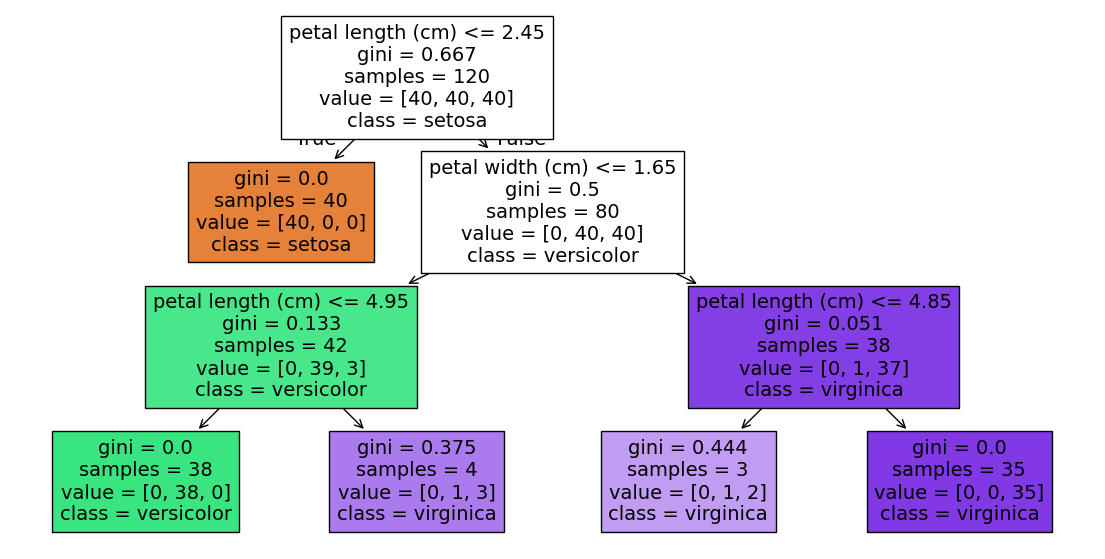

In [2]:
data=load_iris(as_frame=True); X,y=data.data,data.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
tree=DecisionTreeClassifier(max_depth=3,random_state=42).fit(X_train,y_train)
print("Train accuracy:",tree.score(X_train,y_train),"Test accuracy:",tree.score(X_test,y_test))
plt.figure(figsize=(14,7)); plot_tree(tree,feature_names=X.columns,class_names=data.target_names,filled=True); plt.show()

## Compare `max_depth`
A deeper tree may overfit. Compare training and test accuracy.

In [3]:
rows=[]
for depth in [1,2,3,4,5,None]:
 model=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
 rows.append({"max_depth":str(depth),"train_accuracy":model.score(X_train,y_train),"test_accuracy":model.score(X_test,y_test)})
pd.DataFrame(rows).round(3)

,max_depth,train_accuracy,test_accuracy
0,1,0.667,0.667
1,2,0.967,0.933
2,3,0.983,0.967
3,4,0.992,0.933
4,5,1.000,0.933
5,None,1.000,0.933


## Split and leaf constraints
- `min_samples_split`: minimum samples required to split a node.
- `min_samples_leaf`: minimum samples required in a leaf.

In [4]:
rows=[]
for split in [2,5,10]:
 for leaf in [1,2,5]:
  model=DecisionTreeClassifier(max_depth=4,min_samples_split=split,min_samples_leaf=leaf,random_state=42).fit(X_train,y_train)
  rows.append({"min_samples_split":split,"min_samples_leaf":leaf,"test_accuracy":model.score(X_test,y_test)})
pd.DataFrame(rows).sort_values("test_accuracy",ascending=False).round(3)

,min_samples_split,min_samples_leaf,test_accuracy
4,5,2,0.967
7,10,2,0.967
3,5,1,0.967
6,10,1,0.967
0,2,1,0.933
1,2,2,0.933
2,2,5,0.933
5,5,5,0.933
8,10,5,0.933
